[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Y-Robin/MachineLearningKurs/blob/main/set12-zeitreihenanalyse/00_arma_arima_ganz_einfach.ipynb)

**In Colab:** Zuerst die folgende Setup-Zelle ausführen. [Anleitung zum Start](https://colab.research.google.com/github/Y-Robin/MachineLearningKurs/blob/main/set1-python-grundlagen/00_start_mit_google_colab.ipynb).


In [ ]:
# Nur in Google Colab: Repository, Bibliotheken und Arbeitsordner einrichten.
import importlib.util

if (importlib.util.find_spec("google") is not None
        and importlib.util.find_spec("google.colab") is not None):
    from pathlib import Path
    import runpy
    import subprocess

    repo = Path("/content/MachineLearningKurs")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "--branch", "main",
                               "https://github.com/Y-Robin/MachineLearningKurs.git", str(repo)])
    runpy.run_path(str(repo / "colab_setup.py"))["setup"](
        'set12-zeitreihenanalyse/00_arma_arima_ganz_einfach.ipynb', cpu=False)


# Beispiel 00: ARMA und ARIMA ganz einfach

**Die Frage: Wir kennen die bisherigen Messwerte. Was kommt als Nächstes?**

Wir gehen langsam vor: anschauen, Vergangenheit abtrennen, Modell lernen lassen,
40 Werte vorhersagen und die Kurven vergleichen. Die Zellen von oben nach unten ausführen.

**Drei Beispiele:**
1. Eine ruhige Sinuswelle mit wenig Rauschen: ARMA.
2. Ein langsamer Anstieg: ARIMA mit Drift.
3. Anstieg plus Sinuswelle und etwas Rauschen: ARIMA mit Drift und zwei AR-Lags.

Wir verwenden künstliche tägliche Messwerte. Die ersten 120 Tage sind bekannt;
die folgenden 40 Tage werden am Stück vorhergesagt. Die Einstellungen sind zur Erklärung vorgegeben.

## 1. Die Werkzeuge laden

`pandas` verwaltet unsere Messreihe. `matplotlib` zeichnet die Bilder.
**`ARIMA` ist die Modellklasse, die wir für alle drei Beispiele benutzen.**
Du musst keine zusätzlichen Kurs-Hilfsdateien öffnen oder ausführen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 11})

## 2. Erste Messreihe: eine ruhige Welle

Die Werte schwanken regelmäßig um 20 Sensoreinheiten (SE). Ein Durchlauf der Welle dauert 20 Tage.
Ein kleines Rauschen sorgt für leichte Abweichungen. So bleibt die Welle deutlich sichtbar.
Die folgende Zelle erzeugt nur unsere Beispieldaten.

Eine neue, unvorhersehbare Abweichung nennen wir **Schock**. Sie muss nicht groß sein.
Das Modell bekommt später nur die Trainingswerte, nicht die Erzeugungsformel oder die zukünftigen Schocks.

In [2]:
rng = np.random.default_rng(12)
t = np.arange(160)
tage = pd.RangeIndex(1, 161, name="Tag")
rauschen = rng.normal(0, 0.08, len(t))
welle = 3 * np.sin(2 * np.pi * t / 20)
stabil = pd.Series(20 + welle + rauschen, index=tage, name="Messwert")

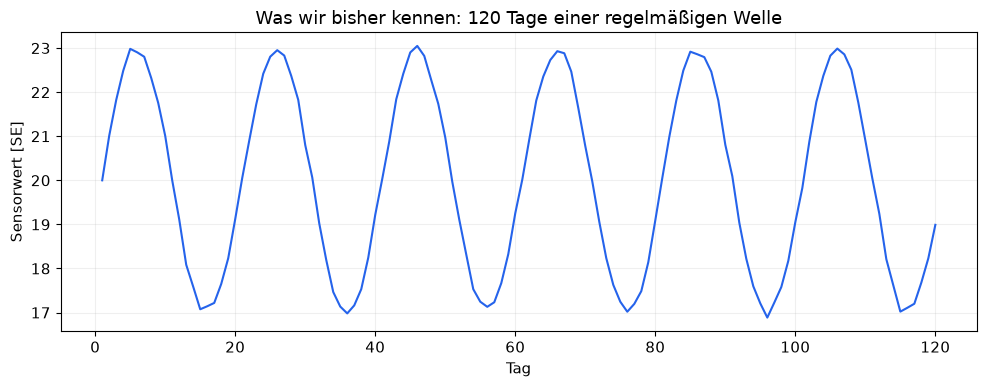

In [3]:
stabil.iloc[:120].plot(color="#2563eb")
plt.title("Was wir bisher kennen: 120 Tage einer regelmäßigen Welle")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.tight_layout()
plt.show()

**Was sagt mir dieser Plot?** Die Welle wiederholt sich und bleibt ungefähr auf demselben Niveau.
Wir möchten dieses Auf und Ab fortsetzen. Der kleine zufällige Anteil ist dabei nicht genau vorhersagbar.

## 3. Vergangenheit und Zukunft trennen

Wir spielen folgende Situation nach: **Heute ist der letzte der ersten 120 Tage.**
Die nächsten 40 Werte halten wir zurück. Sie werden erst später zum Vergleichen verwendet.

In [4]:
training = stabil.iloc[:120]  # Diese 120 Werte darf das Modell sehen.
test = stabil.iloc[120:]     # Diese 40 Werte bleiben beim Lernen verborgen.

print("Bekannte Werte:", len(training))
print("Zurückgehaltene Werte:", len(test))
display(training.tail(3).round(2))

Bekannte Werte: 120
Zurückgehaltene Werte: 40


Tag
118    17.68
119    18.23
120    18.99
Name: Messwert, dtype: float64

## 4. ARMA in drei Zeilen

**AR:** Vergangene Messwerte nutzen. **MA:** Vergangene geschätzte Überraschungen berücksichtigen.
MA ist hier keine Glättung mit `rolling().mean()`.

`order=(2, 0, 1)` bedeutet: **zwei AR-Lags, keine Differenzierung, ein MA-Term**.
Das ist ein **ARMA(2,1)**. Zwei vorherige Werte helfen hier, die Schwingung fortzusetzen;
mit nur einem AR-Lag lässt sich diese Sinuswelle nicht darstellen.

`enforce_stationarity=False` erlaubt hier eine nahezu ungedämpfte Schwingung.
Das ist eine bewusste Einstellung für diese sehr sauberen Lehrdaten, keine allgemeine Empfehlung.

In [5]:
modell = ARIMA(training, order=(2, 0, 1), enforce_stationarity=False)
gelernt = modell.fit(method_kwargs={"maxiter": 1000})
vorhersage = gelernt.forecast(steps=40)

**Zeile für Zeile:**
1. `ARIMA(...)`: Wir legen fest, welche Daten und welche Modellart wir verwenden.
2. `.fit()`: Das Modell schätzt seine Einstellungen aus den bekannten Werten.
3. `.forecast(steps=40)`: Das gelernte Modell liefert 40 zukünftige Werte.

**Alle 40 Prognosen entstehen jetzt.** Dazwischen bekommt das Modell keine echten neuen Messwerte.

`maxiter=1000` erlaubt dem Fit mehr Rechenschritte, falls er sie benötigt.

In [6]:
display(pd.DataFrame({"Vorhersage [SE]": vorhersage}).head(8).round(2))

,Vorhersage [SE]
121,19.91
122,20.84
123,21.69
124,22.37
125,22.82
126,22.99
127,22.87
128,22.47


## 5. Jetzt erst die tatsächlichen Werte aufdecken

**Blau:** bekannte Vergangenheit. **Orange gestrichelt:** Prognose.
**Schwarz:** was später tatsächlich gemessen wurde.
Die senkrechte Linie trennt bekannte Vergangenheit und zurückgehaltene Zukunft.

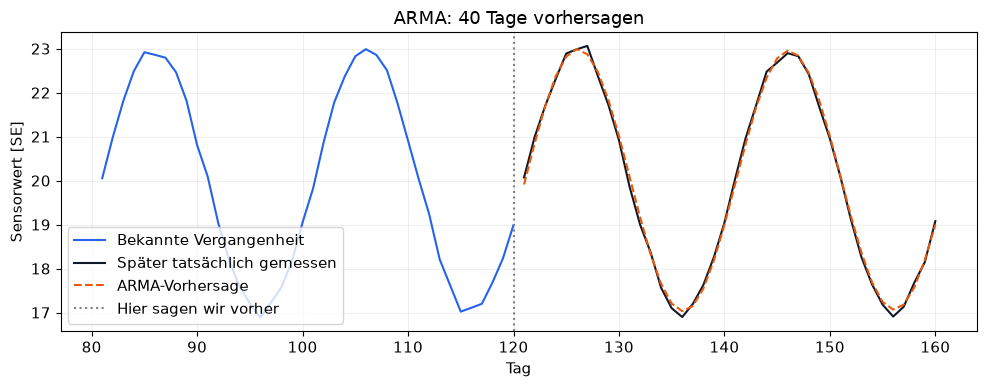

In [7]:
plt.plot(training.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
plt.plot(test, "-", color="#111827", label="Später tatsächlich gemessen")
plt.plot(vorhersage, "--", color="#ea580c", label="ARMA-Vorhersage")
plt.axvline(training.index[-1], color="gray", linestyle=":", label="Hier sagen wir vorher")
plt.title("ARMA: 40 Tage vorhersagen")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.legend()
plt.tight_layout()
plt.show()

**Was soll ich erkennen?** Die orange Prognose setzt die Welle über zwei weitere Durchläufe fort.
Sie liegt bei diesen sauberen Daten nahe an den später gemessenen Werten.
Kleine Abweichungen bleiben: Die zukünftigen Zufallsschwankungen waren unbekannt.

Die Welle wird aus den Trainingswerten gelernt. Wir übergeben weder ihre Formel noch ihre
zukünftigen Messwerte an das Modell. ARMA kann nicht jede beliebige Kurve fortsetzen;
hier passen zwei AR-Lags zur regelmäßigen Schwingung.

## 6. Zweite Messreihe: ein langsamer Anstieg

Jetzt wächst der Sensorwert ungefähr um 0,6 SE pro Tag. Dazu kommen kleine Schwankungen.
Die Datenquelle ist wieder vorgegeben. Das Modell bekommt später nur die Messwerte,
**nicht** den Wert 0,6 und **nicht** die zukünftigen Schocks.

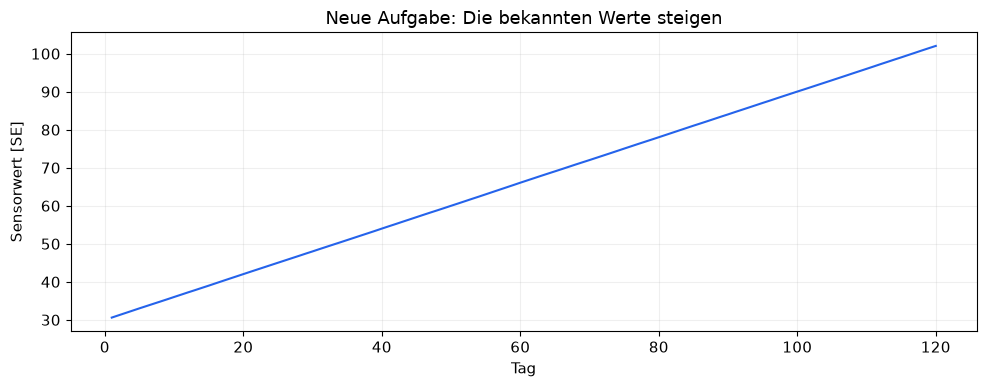

In [8]:
steigend = pd.Series(30 + np.cumsum(0.6 + 0.1 * rauschen), index=tage, name="Messwert")
training_trend = steigend.iloc[:120]
test_trend = steigend.iloc[120:]

training_trend.plot(color="#2563eb")
plt.title("Neue Aufgabe: Die bekannten Werte steigen")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.tight_layout()
plt.show()

**Was sagt mir dieser Plot?** Ein dauerhaft gleichbleibendes Grundniveau passt hier nicht.
Wir möchten den bisher beobachteten Anstieg berücksichtigen.

## 7. Was bedeutet Differenzierung ganz einfach?

Wir betrachten den Unterschied zum vorherigen Wert:

| Messwerte | Veränderung gegenüber dem vorherigen Wert |
|---|---|
| 10 | noch nicht berechenbar |
| 12 | +2 |
| 14 | +2 |
| 16 | +2 |

Die Messwerte steigen. Ihre Veränderungen bleiben in diesem kleinen Beispiel konstant.
Wenn wir als nächste Veränderung +2 erwarten, lautet die nächste Messwertprognose **16 + 2 = 18**.

**Das ist die Idee hinter dem I in ARIMA:** Veränderungen modellieren und für die Prognose
wieder zu Messwerten zurückrechnen. Die Bibliothek übernimmt beides.

In [9]:
# Nur zum Anschauen: Wir geben diese Differenzen NICHT zusätzlich an ARIMA weiter.
display(pd.DataFrame({
    "Messwert [SE]": training_trend.tail(5),
    "Änderung zum Vortag [SE]": training_trend.diff().tail(5)
}).round(2))

,Messwert [SE],Änderung zum Vortag [SE]
Tag,,
116,99.63,0.61
117,100.24,0.61
118,100.85,0.61
119,101.45,0.60
120,102.04,0.59


## 8. ARIMA: wieder nur drei Zeilen

`order=(1, 1, 1)` bedeutet: ein AR-Lag, **einmal differenzieren**, ein MA-Term.
Die AR- und MA-Anteile wirken jetzt auf die Veränderungen.

**`trend="t"` ist hier wichtig:** Bei `d=1` erlaubt diese Einstellung einen konstanten
mittleren Anstieg der ursprünglichen Werte, auch **Drift** genannt. Das Modell lernt dessen Größe.
`d=1` allein garantiert noch keine steigende Prognose.

Wir übergeben weiterhin die **ursprünglichen Messwerte**. Nicht vorher selbst `.diff()` darauf anwenden!

In [10]:
modell_trend = ARIMA(training_trend, order=(1, 1, 1), trend="t")
gelernt_trend = modell_trend.fit()
vorhersage_trend = gelernt_trend.forecast(steps=40)

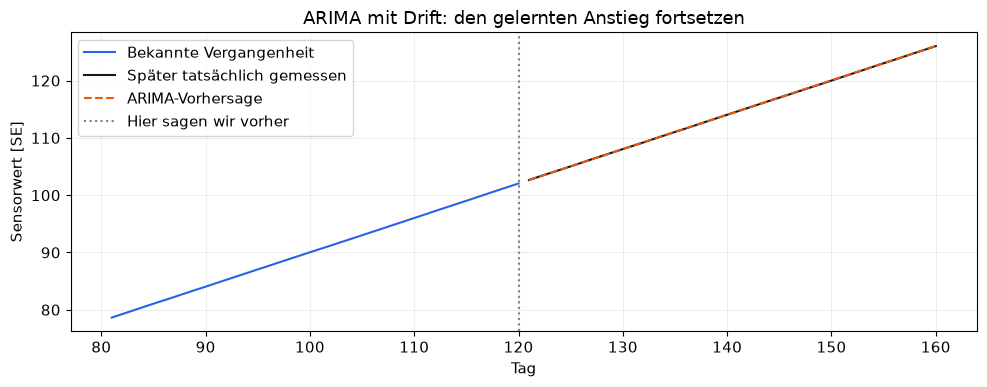

In [11]:
plt.plot(training_trend.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
plt.plot(test_trend, "-", color="#111827", label="Später tatsächlich gemessen")
plt.plot(vorhersage_trend, "--", color="#ea580c", label="ARIMA-Vorhersage")
plt.axvline(training_trend.index[-1], color="gray", linestyle=":", label="Hier sagen wir vorher")
plt.title("ARIMA mit Drift: den gelernten Anstieg fortsetzen")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.legend()
plt.tight_layout()
plt.show()

**Was sagt mir dieser Plot?** Die orange Prognose setzt den gelernten Anstieg fort.
Sie ist bereits wieder in **Sensoreinheiten**, nicht in Differenzen.
Die schwarze Messkurve weicht ab, weil die zukünftigen Überraschungen unbekannt waren.

ARIMA weiß nicht, dass es auch morgen weiter bergauf geht. Es schreibt die gelernte Struktur fort.
Wenn sich das Verhalten plötzlich ändert, kann diese Prognose falsch liegen.

## 9. Ist das besser als eine ganz einfache Vermutung?

Unsere einfache Vergleichsprognose lautet: **Alle nächsten Werte sind gleich dem letzten bekannten Wert.**
Sie heißt auch Baseline. Sie erhält dieselbe Vergangenheit wie ARIMA.

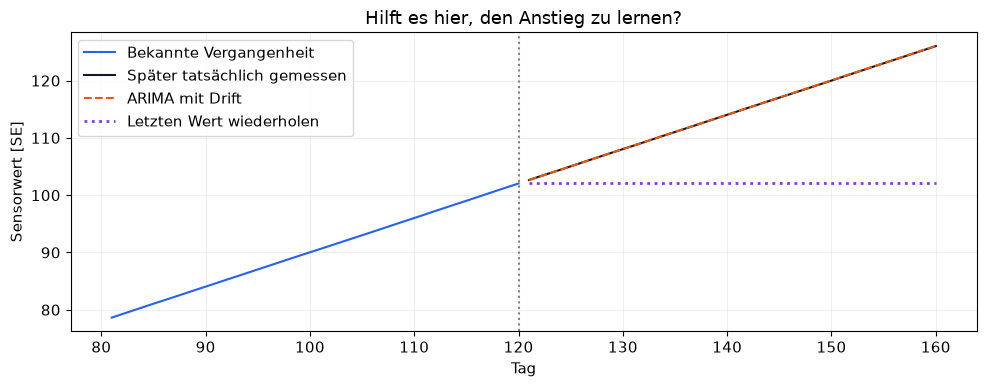

In [12]:
einfach = pd.Series(training_trend.iloc[-1], index=test_trend.index)

plt.plot(training_trend.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
plt.plot(test_trend, "-", color="#111827", label="Später tatsächlich gemessen")
plt.plot(vorhersage_trend, "--", color="#ea580c", label="ARIMA mit Drift")
plt.plot(einfach, ":", color="#7c3aed", linewidth=2, label="Letzten Wert wiederholen")
plt.axvline(training_trend.index[-1], color="gray", linestyle=":")
plt.title("Hilft es hier, den Anstieg zu lernen?")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.legend()
plt.tight_layout()
plt.show()

**So liest du das Bild:** Die violette Linie bleibt stehen. Die orange Linie steigt.
Vergleiche beide mit der schwarzen Messkurve. Bei diesen vorbereiteten Daten hilft der gelernte Anstieg.
Das ist keine Garantie, dass ARIMA auf beliebigen Daten gewinnt.

Wir messen den durchschnittlichen absoluten Abstand: **MAE**.
Eine Abweichung von −2 zählt dabei genauso viel wie +2. Kleiner ist besser.

In [13]:
fehler_arima = (test_trend - vorhersage_trend).abs().mean()
fehler_einfach = (test_trend - einfach).abs().mean()

print(f"ARIMA: durchschnittlich {fehler_arima:.2f} SE daneben")
print(f"Letzter Wert: durchschnittlich {fehler_einfach:.2f} SE daneben")
display(pd.DataFrame({
    "Tatsächlich": test_trend,
    "ARIMA": vorhersage_trend,
    "Letzter Wert": einfach
}).round(2))

ARIMA: durchschnittlich 0.02 SE daneben
Letzter Wert: durchschnittlich 12.29 SE daneben


,Tatsächlich,ARIMA,Letzter Wert
121,102.65,102.64,102.04
122,103.25,103.24,102.04
123,103.84,103.84,102.04
124,104.43,104.44,102.04
125,105.04,105.04,102.04
126,105.64,105.64,102.04
127,106.26,106.24,102.04
128,106.85,106.84,102.04
129,107.45,107.44,102.04
130,108.05,108.04,102.04


## 10. Jetzt zusammen: Anstieg, Sinus und Rauschen

Nun steigt das Grundniveau langsam, und darauf liegt dieselbe regelmäßige Welle.
Die kleinen zufälligen Abweichungen bleiben erhalten.

**Was soll das Modell vorhersagen?** Sowohl den weiteren Anstieg als auch das Auf und Ab.
Die einzelnen zufälligen Zacken kann es nicht kennen.

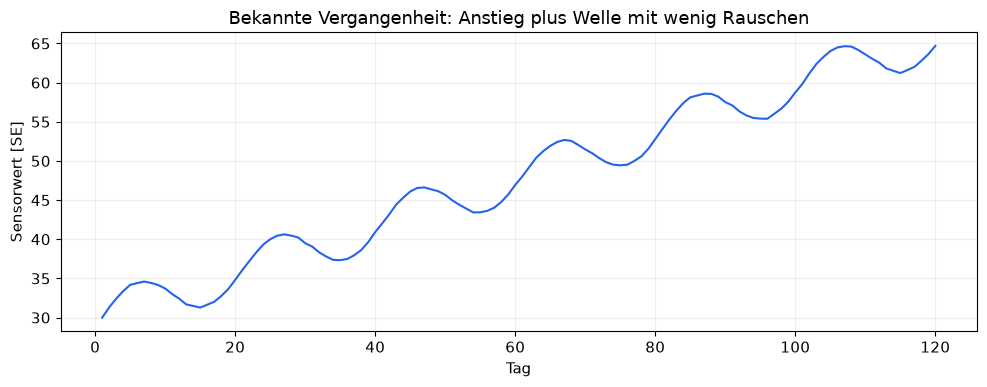

In [14]:
kombiniert = pd.Series(30 + 0.3 * t + welle + rauschen, index=tage, name="Messwert")
training_kombi = kombiniert.iloc[:120]
test_kombi = kombiniert.iloc[120:]

training_kombi.plot(color="#2563eb")
plt.title("Bekannte Vergangenheit: Anstieg plus Welle mit wenig Rauschen")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.tight_layout()
plt.show()

Wir verwenden wieder `ARIMA`. Gegenüber dem linearen Beispiel ändern wir `p` von 1 auf 2:

- **p=2:** Zwei AR-Lags können hier die Schwingung beschreiben.
- **d=1:** Die Reihe wird einmal differenziert.
- **q=1:** Ein vergangener geschätzter Schock wird berücksichtigt.
- **`trend="t"`:** Bei d=1 darf das Modell einen mittleren Anstieg lernen.

Auch die Differenzen einer Sinuswelle schwingen. Differenzieren allein entfernt die Welle also nicht.
Hier beschreibt der AR-Anteil das verbliebene Auf und Ab.

In [15]:
modell_kombi = ARIMA(training_kombi, order=(2, 1, 1), trend="t", enforce_stationarity=False)
gelernt_kombi = modell_kombi.fit(method_kwargs={"maxiter": 1000})
vorhersage_kombi = gelernt_kombi.forecast(steps=40)

Y:\Consulting\alfa\MachineLearning-Kurs\Code\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


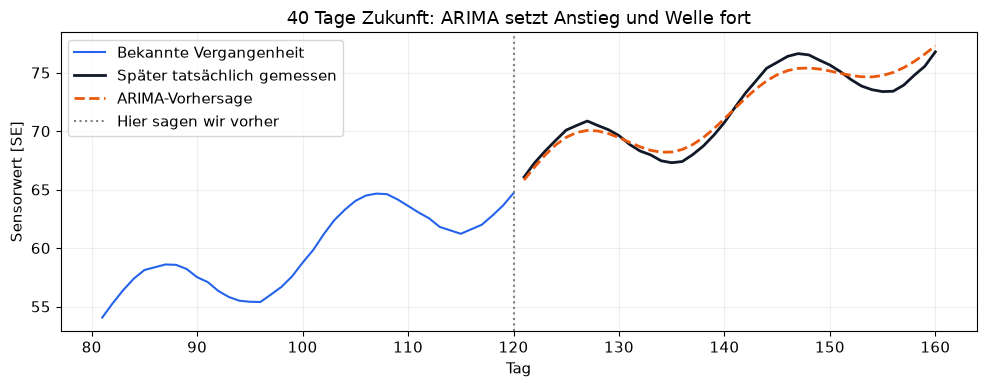

Durchschnittlicher absoluter Fehler: 0.71 SE


In [16]:
plt.plot(training_kombi.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
plt.plot(test_kombi, color="#111827", linewidth=2, label="Später tatsächlich gemessen")
plt.plot(vorhersage_kombi, "--", color="#ea580c", linewidth=2, label="ARIMA-Vorhersage")
plt.axvline(training_kombi.index[-1], color="gray", linestyle=":", label="Hier sagen wir vorher")
plt.title("40 Tage Zukunft: ARIMA setzt Anstieg und Welle fort")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Durchschnittlicher absoluter Fehler: {(test_kombi - vorhersage_kombi).abs().mean():.2f} SE")

**Was sagt mir dieser Plot?** Die Prognose steigt und schwingt zugleich.
Sie enthält bereits die ursprünglichen Messwerte, keine Differenzen.
Alle 40 Vorhersagen wurden am Ende von Tag 120 erstellt. Kein echter Wert aus den Tagen 121–160
wurde beim Lernen oder zwischen den Vorhersageschritten nachgereicht.

Das Beispiel ist absichtlich klar und rauscharm. Es zeigt, dass ein passendes Modell
ein regelmäßiges Muster fortsetzen kann. Größeres Rauschen oder ein Wechsel des Musters
können die Vorhersage deutlich verschlechtern.

## 11. Was passiert, wenn wir bei einem Trend ARMA verwenden?

Jetzt bekommt **ARMA dieselben Trainingswerte mit Anstieg und Sinus** wie ARIMA.
Beide sagen am Ende von Tag 120 dieselben 40 Tage vorher. Beide verwenden zwei AR-Lags und einen MA-Term.

| Modell | Einstellung | Was nehmen wir an? |
|---|---|---|
| ARMA(2,1) | `order=(2, 0, 1), trend="c"` | Keine Differenzierung, ein konstantes Grundniveau |
| ARIMA(2,1,1) | `order=(2, 1, 1), trend="t"` | Veränderungen modellieren und einen mittleren Anstieg lernen |

**Unsere Frage:** Reicht das ARMA-Modell aus dem Wellenbeispiel auch dann noch, wenn das Niveau ständig steigt?
Wir vergleichen hier bewusst ARMA ohne ausdrücklichen Trend mit ARIMA mit Drift.


In [17]:
modell_arma_trend = ARIMA(training_kombi, order=(2, 0, 1), trend="c", enforce_stationarity=False)
gelernt_arma_trend = modell_arma_trend.fit(method_kwargs={"maxiter": 1000})
vorhersage_arma_trend = gelernt_arma_trend.forecast(steps=40)


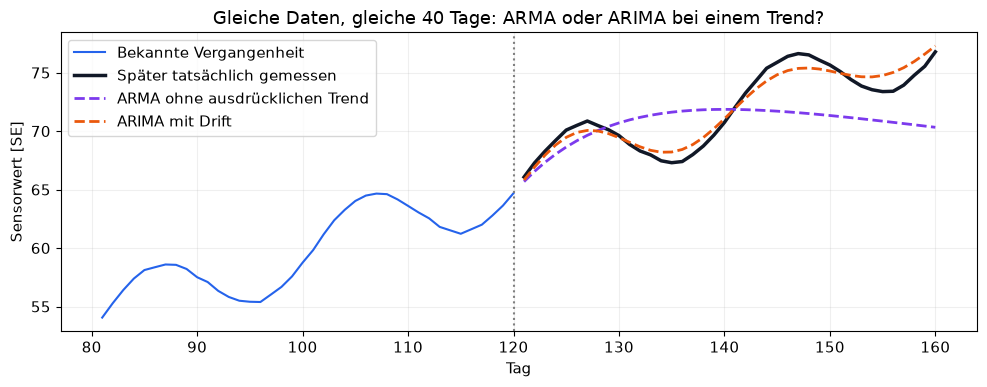

,Modell,Durchschnittlicher Fehler [SE]
0,ARMA ohne ausdrücklichen Trend,2.82
1,ARIMA mit Drift,0.71


In [18]:
plt.plot(training_kombi.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
plt.plot(test_kombi, color="#111827", linewidth=2.5, label="Später tatsächlich gemessen")
plt.plot(vorhersage_arma_trend, "--", color="#7c3aed", linewidth=2, label="ARMA ohne ausdrücklichen Trend")
plt.plot(vorhersage_kombi, "--", color="#ea580c", linewidth=2, label="ARIMA mit Drift")
plt.axvline(training_kombi.index[-1], color="gray", linestyle=":")
plt.title("Gleiche Daten, gleiche 40 Tage: ARMA oder ARIMA bei einem Trend?")
plt.xlabel("Tag")
plt.ylabel("Sensorwert [SE]")
plt.legend()
plt.tight_layout()
plt.show()

mae_arma_trend = (test_kombi - vorhersage_arma_trend).abs().mean()
mae_arima_trend = (test_kombi - vorhersage_kombi).abs().mean()
display(pd.DataFrame({
    "Modell": ["ARMA ohne ausdrücklichen Trend", "ARIMA mit Drift"],
    "Durchschnittlicher Fehler [SE]": [mae_arma_trend, mae_arima_trend]
}).round(2))


**Was soll ich erkennen?** Die orange ARIMA-Prognose folgt dem weiteren Anstieg und dem Auf und Ab.
Die violette ARMA-Prognose bildet diese Kombination hier schlechter ab. In der Tabelle sieht man das
am größeren durchschnittlichen absoluten Fehler. **Kleiner ist besser.**

**Warum?** Das ARMA-Modell muss die steigenden Messwerte direkt beschreiben, ohne dass wir ihm
einen ausdrücklichen Trend erlauben. ARIMA betrachtet stattdessen die Veränderungen.
Mit `trend="t"` lernt es deren mittleren Anstieg; die AR-Lags beschreiben die verbleibende Welle.

**Merksatz für dieses Beispiel:** Bei der reinen Welle hat ARMA gut funktioniert.
Kommt ein Anstieg hinzu, hilft hier ARIMA mit Differenzierung und Drift.

Das bedeutet nicht, dass ARMA bei jedem Trend zwingend schlechter ist. Man könnte einen Trend
auch vorher entfernen oder ausdrücklich mitmodellieren. Hier ändern wir sowohl die Differenzierung
als auch die Trendannahme; wir zeigen keinen isolierten Effekt von `d` allein.


## 12. Drei Merksätze reichen für den Anfang

1. **ARMA:** vergangene Werte und vergangene geschätzte Überraschungen nutzen.
2. **ARIMA:** zusätzlich differenzieren; die Vorhersage wird wieder auf die ursprünglichen Werte zurückgerechnet.
3. **Der Ablauf bleibt gleich:** `ARIMA(...)` → `.fit()` → `.forecast(...)`.

| Frage | Antwort für unsere Beispiele |
|---|---|
| Warum heißt der Aufruf auch bei ARMA `ARIMA`? | `d=0` schaltet die Differenzierung aus. |
| Was bedeutet `(2, 0, 1)`? | Zwei AR-Lags, keine Differenzierung, ein MA-Term. |
| Was bedeutet `(1, 1, 1)`? | Ein AR-Lag, einmal differenzieren, ein MA-Term. |
| Woher kennt das Modell den Anstieg? | Es lernt ihn; hier erlaubt `trend="t"` bei `d=1` eine Drift. |
| Warum trifft es nicht jeden Punkt? | Zukünftige Überraschungen sind unbekannt. |
| Muss ich ACF und PACF vorher verstehen? | Für diesen ersten Durchlauf nicht. |

**Grenze dieses Einstiegs:** Wir haben Modellarten vorher festgelegt und einen späteren Abschnitt geprüft.
Wir haben keine optimale Modellwahl durchgeführt. Wer Einstellungen anhand dieser Testwerte verändert,
braucht für eine unabhängige Abschlussbewertung einen weiteren unberührten Zeitraum.

**Als Nächstes:** [Übung 00 mit einfachen Fragen](uebungen/00_uebung_arma_arima_einfach.ipynb).
Danach kannst du in 03b die Modellmechanismen und in 04 weitere Prognosevergleiche vertiefen.